In [15]:
c = (0.0, 0.0)
r = 0.2
R = 1.0

In [16]:
M = [(1.0, 2.0)]

In [17]:
import torch
torch.set_default_dtype(torch.double)

In [18]:
N = 11
angle = torch.rand((N, 1)) * 2 * torch.pi

xy_omega_in = r * torch.cat( (torch.cos(angle), torch.sin(angle)), dim=-1 )
xy_omega_out = R * torch.cat( (torch.cos(angle), torch.sin(angle)), dim=-1 )

mu = torch.rand((N, 1))

In [19]:
def ustar(
    xy: torch.Tensor, mu: torch.Tensor, c: torch.Tensor=torch.tensor(c), r: float=r, R: float=R
) -> torch.Tensor:
    # Fill this function
    xynorm = torch.linalg.norm(xy-c, dim=1, keepdim=True)
    num = R**2 - r**2
    denom = torch.log(torch.tensor(R / r))
    res = (R**2 - xynorm**2) + (num / denom) * torch.log(xynorm / R)
    res *= (1.0 / (4 * mu))
    return res
print(ustar(xy_omega_in,mu).shape)

torch.Size([11, 1])


In [20]:
print(xy_omega_in.shape)

torch.Size([11, 2])


In [21]:
# Fill the asserts below
# hint: torch.zeros((m,n)) generates a tensor of shape (m,n) filled with 0.
assert torch.allclose( ustar(xy_omega_in, mu), torch.zeros((N,1)))
assert torch.allclose( ustar(xy_omega_out, mu), torch.zeros((N,1)))

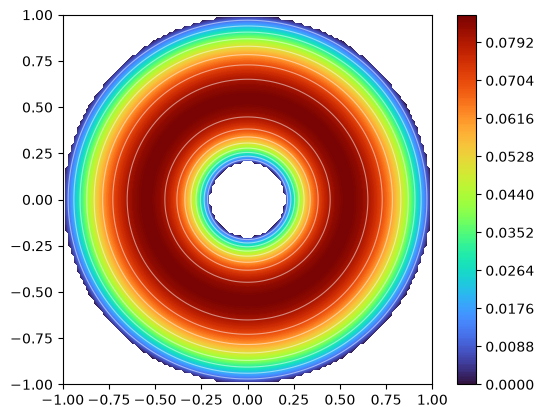

In [22]:
import matplotlib.pyplot as plt
import numpy as np

def plot_func_on_circle(func, mu=1., c=np.array(c), r=r, R=R, n_visu=128):

    bb = np.stack( (c-R, c+R), axis = 0 ).T
    x = np.linspace( bb[0, 0], bb[0, 1], n_visu )
    y = np.linspace( bb[1, 0], bb[1, 1], n_visu )
    x, y = np.meshgrid(x, y)
    xy = np.stack((x, y), axis=-1).reshape((n_visu**2, 2))
    mask = (np.linalg.norm( (xy-c), axis=-1 ) >= R) | (np.linalg.norm( (xy-c), axis=-1 ) <= r)

    e = func(torch.tensor(xy), mu*torch.ones((n_visu**2, 1)), torch.tensor(c), r)
    e = e.cpu().detach().numpy().reshape((n_visu, n_visu))
    e = np.ma.array(e, mask=mask)
    fig = plt.figure()
    axe = fig.add_subplot(1, 1, 1)
    im = axe.contourf(x, y, e, 256, vmax=e.max(), cmap="turbo", zorder=-9)
    axe.contour(im, levels=im.levels[:: 256 // 10], zorder=-9, colors="white", alpha=0.5, linewidths=0.8)
    fig.colorbar(im, ax=axe)
    axe.set_aspect("equal")

    plt.show()

plot_func_on_circle(ustar)

In [23]:
t = torch.rand((1,)) #the value with respect to which we differentiate
t.requires_grad_() #tell torch to track gradients with respect to t
ft = torch.acos(torch.cos(t))
dfdt, = torch.autograd.grad(ft, t) #compute the gradient of f(t) with respect to t
print("dfdt.shape: ", dfdt.shape)
print("dfdt: ", dfdt)

dfdt.shape:  torch.Size([1])
dfdt:  tensor([1.0000], device='cuda:0')


In [24]:
N = 11
angle = torch.rand((N, 1)) * 2 * torch.pi
norm = r + torch.rand((N, 1)) * (R - r)
xy = norm * torch.cat( (torch.cos(angle), torch.sin(angle)), dim=-1 )
mu = torch.rand((N, 1))

xy.requires_grad_()
u = ustar(xy, mu)
dudxy, = torch.autograd.grad(u, xy, torch.ones_like(u), create_graph=True)
print("dudxy.shape: ", dudxy.shape)

dudxy.shape:  torch.Size([11, 2])


In [25]:
dudxy, = torch.autograd.grad(u, xy, torch.ones_like(u), create_graph=True)

# fill the code below:
dudx, dudy = dudxy[:, 0:1], dudxy[:, 1:2]
dudxxy, = torch.autograd.grad(dudx, xy, torch.ones_like(dudx), create_graph=True)
dudyxy, = torch.autograd.grad(dudy, xy, torch.ones_like(dudy), create_graph=True)
dudxx = dudxxy[:, 0:1]
dudyy = dudyxy[:, 1:2]
print("dudxx.shape: ", dudxx.shape)
print("dudyy.shape: ", dudyy.shape)
lefthandside = -mu*(dudxx + dudyy)
assert torch.allclose(lefthandside, torch.ones(N, 1))

dudxx.shape:  torch.Size([11, 1])
dudyy.shape:  torch.Size([11, 1])


In [26]:
#pip install scimba

In [27]:
import scimba_torch

scimba_torch.set_verbosity(True)
scimba_torch.set_verbosity(False)


/////////////// Scimba 1.4.1 ////////////////
torch device: cuda:0
torch floating point format: torch.float64
cuda devices:        1
cuda current device: 0
cuda device name:    NVIDIA GeForce RTX 3090




In [28]:
from scimba_torch.domain.meshless_domain.domain_2d import Disk2D

# disk centered in c of radius R
Omega = Disk2D(c, R, is_main_domain=True)

In [29]:
# fill the code below:
hole = Disk2D(c, r, is_main_domain=False)

In [30]:
Omega.add_hole(hole)

In [31]:
from scimba_torch.integration.monte_carlo import DomainSampler

sampler_Omega = DomainSampler(Omega)

In [32]:
xy = sampler_Omega.sample(1000)
xy_bc, n_bc = sampler_Omega.bc_sample(2000)

print("xy.shape: ", xy.shape, "xy_bc.shape: ", xy_bc.shape, "n_bc.shape: ", n_bc.shape)

xy.shape:  torch.Size([1000, 2]) xy_bc.shape:  torch.Size([2000, 2]) n_bc.shape:  torch.Size([2000, 2])


In [33]:
print("0-th point: ", xy_bc.x[0])
print("normal at 0-th point: ", n_bc.x[0])

0-th point:  tensor([-0.8064,  0.5913], device='cuda:0', grad_fn=<SelectBackward0>)
normal at 0-th point:  tensor([-0.8064,  0.5913], device='cuda:0', grad_fn=<SelectBackward0>)


In [34]:
x, y = xy.get_components()
x_bc, y_bc = xy_bc.get_components()

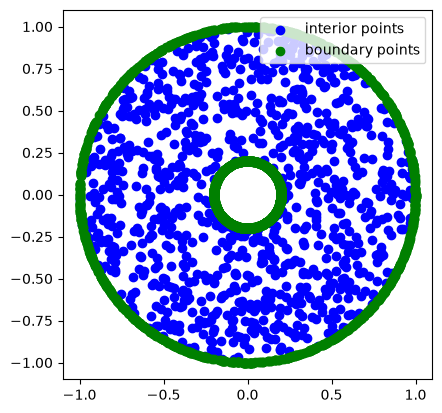

In [35]:
x = x.cpu().detach().numpy()
y = y.cpu().detach().numpy()
x_bc = x_bc.cpu().detach().numpy()
y_bc = y_bc.cpu().detach().numpy()

import matplotlib.pyplot as plt

fig = plt.figure()
axe = fig.add_subplot(1, 1, 1)
axe.scatter(x, y, color="b", label="interior points")
axe.scatter(x_bc, y_bc, color="g", label="boundary points")
axe.set_aspect("equal")
axe.legend()
plt.show()

In [36]:
from scimba_torch.integration.monte_carlo import TensorizedSampler
from scimba_torch.integration.monte_carlo_parameters import UniformParametricSampler

sampler_M = UniformParametricSampler(M)
sampler = TensorizedSampler([sampler_Omega, sampler_M])

# sample Omega and its boundary
N = 1000
N_bc = 1000
xy, mu = sampler.sample(N)
(xy_bc, n_bc), mu_bc = sampler.bc_sample(N_bc, index_bc=0)

Approximation space

In [37]:
from scimba_torch.approximation_space.nn_space import NNxSpace
from scimba_torch.neural_nets.coordinates_based_nets.mlp import GenericMLP

u_theta = NNxSpace(
    1,  # the output dimension
    1,  # the parameter's space dimension
    GenericMLP,  # the type of neural network, here a MLP
    Omega,  # the geometric domain
    sampler,  # the sampler
    layer_sizes=[32, 32],  # the size of intermediate layers
)

# evaluate NNxSpace on x, mu:
w = u_theta.evaluate(xy, mu)
w.shape

torch.Size([1000, 1])

In [38]:
w_bc = u_theta.evaluate(xy_bc, mu_bc)

u_bc = w_bc.get_components()

assert u_bc.shape == (xy_bc.shape[0], 1)

In [39]:
u = w.get_components()
u.shape

torch.Size([1000, 1])

In [40]:
u_x, u_y = u_theta.grad(w, xy)
u_x_bc, u_y_bc = u_theta.grad(w_bc, xy_bc)

In [41]:
import torch
from scimba_torch.utils.scimba_tensors import LabelTensor, MultiLabelTensor


def f_rhs(xy: LabelTensor, mu: LabelTensor) -> torch.Tensor:
    x, _ = xy.get_components()
    return torch.ones_like(x)

In [42]:
from scimba_torch.approximation_space.abstract_space import AbstractApproxSpace


def main_operator(
    space: AbstractApproxSpace, w: MultiLabelTensor, xy: LabelTensor, mu: LabelTensor
) -> torch.Tensor:
    u = w.get_components()
    mu = mu.get_components()
    # fill the code below
    # compute u_xx and u_yy, the second order derivatives with respect to x and y
    u_x, u_y = space.grad(u, xy)
    u_xx, _ = space.grad(u_x, xy)
    _, u_yy = space.grad(u_y, xy)
    return -mu * (u_xx + u_yy)

In [43]:
xy, mu = sampler.sample(N)
w = u_theta.evaluate(xy, mu)
Left = main_operator(u_theta, w, xy, mu)
assert Left.shape == (N, 1)

In [44]:
def exact_sol(xy: LabelTensor, mu: LabelTensor, c=torch.tensor(c), r=r, R=R) -> MultiLabelTensor:
    res = ustar(xy.x, mu.x, c, r, R)
    return MultiLabelTensor(res, [xy.labels])


class mspace:
    def grad(
        self, u: torch.Tensor | MultiLabelTensor, x: torch.Tensor | LabelTensor
    ) -> torch.Tensor:
        if isinstance(u, MultiLabelTensor):
            u = u.w
        if isinstance(x, LabelTensor):
            x = x.x
        (dudx,) = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)
        if x.size(1) > 1:
            return (dudx[:, i, None] for i in range(x.size(1)))
        else:
            return dudx[:, 0, None]


w = exact_sol(xy, mu)
uspace = mspace()

assert torch.allclose(main_operator(uspace, w, xy, mu), torch.ones_like(w.w))

In [45]:
def g_rhs(xy: LabelTensor, mu: LabelTensor) -> torch.Tensor:
    x, _ = xy.get_components()
    return torch.zeros_like(x)

In [46]:
def boundary_operator(
    space: AbstractApproxSpace,
    w: MultiLabelTensor,
    xy: LabelTensor,
    n: LabelTensor,
    mu: LabelTensor,
) -> torch.Tensor:
    # Fill the code below
    # Dirichlet condition on boundary circles:
    u = w.get_components()
    return u

In [47]:
(xy_bc, n_bc), mu_bc = sampler.bc_sample(N_bc, index_bc=0)
w_bc = u_theta.evaluate(xy_bc, mu_bc)
Left = boundary_operator(u_theta, w_bc, xy_bc, n_bc, mu_bc)
Right = g_rhs(xy_bc, mu_bc)
assert Left.shape == Right.shape

In [48]:
w_bc = exact_sol(xy_bc, mu_bc)
Left = boundary_operator(uspace, w_bc, xy_bc, n_bc, mu_bc)
Right = g_rhs(xy_bc, mu_bc)
assert torch.allclose(Left, Right)

In [49]:
from scimba_torch.physical_models.elliptic_pde.abstract_elliptic_pde import (
    StrongFormEllipticPDE,
)


class Laplacian2DDirichletStrongForm(StrongFormEllipticPDE):
    def __init__(self, space: AbstractApproxSpace, **kwargs):
        super().__init__(space, residual_size=1, bc_residual_size=1, **kwargs)

    def rhs(
        self, w: MultiLabelTensor, xy: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        return f_rhs(xy, mu)

    def operator(
        self, w: MultiLabelTensor, xy: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        return main_operator(self.space, w, xy, mu)

    def bc_rhs(
        self, w: MultiLabelTensor, xy: LabelTensor, n: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        return g_rhs(xy, mu)

    def bc_operator(
        self, w: MultiLabelTensor, xy: LabelTensor, n: LabelTensor, mu: LabelTensor
    ) -> torch.Tensor:
        return boundary_operator(self.space, w, xy, n, mu)

In [50]:
pde = Laplacian2DDirichletStrongForm(u_theta)

In [51]:
from scimba_torch.numerical_solvers.elliptic_pde.pinns import PinnsElliptic
import timeit

pinn = PinnsElliptic(
    pde,
    bc_type="weak",  # handle weakly the boundary conditions
    bc_weight=30.,  # balance loss of the boundary conditions / residual
)

n_epochs=1000
n_collocation=2000
n_bc_collocation=2000

start = timeit.default_timer()
pinn.solve(epochs=n_epochs, n_collocation=n_collocation, n_bc_collocation=n_bc_collocation)
end = timeit.default_timer()

print("loss after optimization: ", pinn.best_loss)
print("approximation time: %f s" % (end - start))

Training: 100%|||||||||||||||| 1000/1000[00:32<00:00] , loss: 9.7e-01 -> 1.5e-01
loss after optimization:  0.14982586834417166
approximation time: 33.888061 s


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


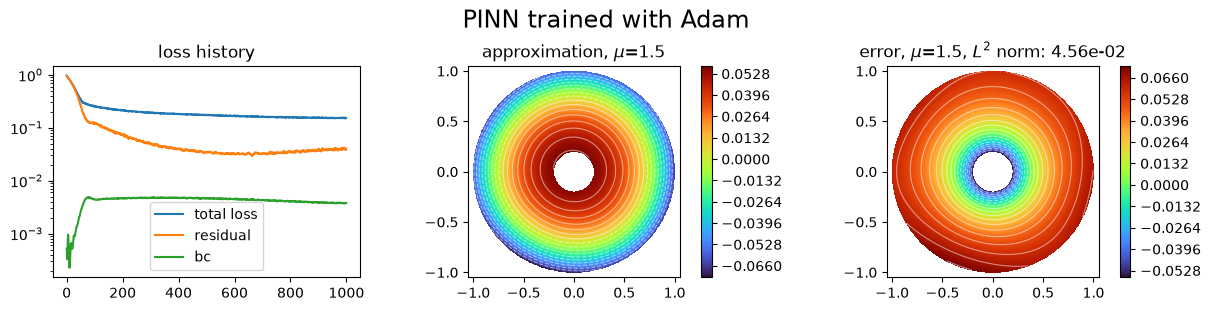

In [52]:
from scimba_torch.plots.plots_nd import plot_abstract_approx_spaces

def exact_sol_for_plot(
    xy: LabelTensor, mu: LabelTensor, c=torch.tensor(c), r=r, R=R
) -> torch.Tensor:
    return ustar(xy.x, mu.x, c, r, R)

plot_abstract_approx_spaces(
    pinn.space,
    Omega,
    M,
    loss=pinn.losses,
    draw_contours=True,
    n_drawn_contours=20,
    error=exact_sol_for_plot,
    title="PINN trained with Adam",
    n_visu=512,
)

Training:   1%|                 | 7/1000[00:00<01:21] , loss: 1.4e+00 -> 3.0e-01

Training: 100%|||||||||||||||| 1000/1000[00:52<00:00] , loss: 1.4e+00 -> 1.1e-04
loss after optimization:  0.00011168025351824454
approximation time: 52.738514 s


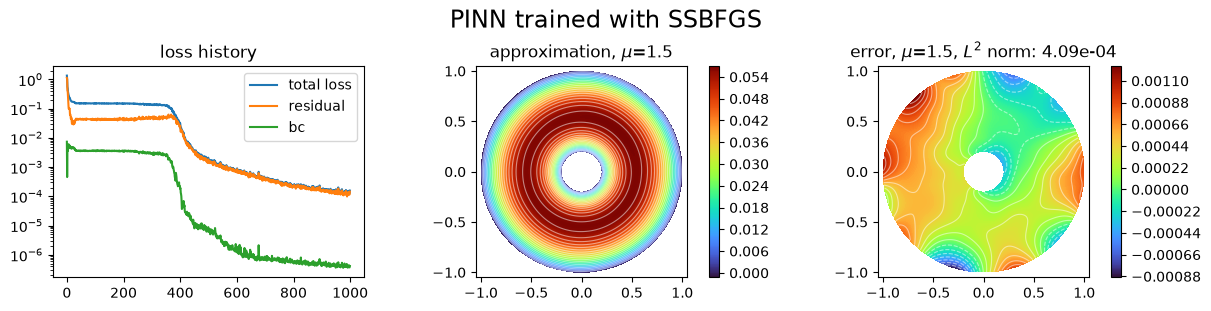

In [53]:
u_theta = NNxSpace(1, 1, GenericMLP, Omega, sampler, layer_sizes=[32, 32])
pde = Laplacian2DDirichletStrongForm(u_theta)

pinn = PinnsElliptic(
    pde,
    bc_type="weak",  # handle weakly the boundary conditions
    bc_weight=30.,  # balance loss of the boundary conditions / residual
    optimizers="ssbfgs"
)

start = timeit.default_timer()
pinn.solve(epochs=n_epochs, n_collocation=n_collocation, n_bc_collocation=n_bc_collocation)
end = timeit.default_timer()

print("loss after optimization: ", pinn.best_loss)
print("approximation time: %f s" % (end - start))

plot_abstract_approx_spaces(
    pinn.space,
    Omega,
    M,
    loss=pinn.losses,
    draw_contours=True,
    n_drawn_contours=20,
    error=exact_sol_for_plot,
    title="PINN trained with SSBFGS",
    n_visu=512,
)